# 05 - The Poisson fit, one stage at a time

One epoch through the whole fit: inputs -> initial guesses -> stage A (core) ->
B (halo) -> C (strahl) -> D (joint) -> physical parameters. Every stage is drawn with
the pixels it used.

**Runtime:** 1-2 minutes (the fit takes about 10 s; the rest is plotting).

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 0. Inputs and initial guesses

Per epoch the fit needs the pixel grid (`loadEpoch`), the break energy (crossing CSV)
and the PAD verdict (`detectStrahlFromPad`); see notebooks 01 and 03. `seedFromData`
turns them into initial guesses (notebook 04):

- **core:** density and widths from the moments of the pixels below 70 eV;
- **halo:** 3 % of the core density, five times hotter, at rest ($u_{\parallel h} = 0$);
- **strahl:** on the side the PAD found, perpendicular width anchored to the PAD width.

In [2]:
from evdf_poisson import loadEpoch, detectStrahlFromPad, seedFromData, componentMomentsFromParams
from evdf_poisson.models import temperatureFromThermalSpeed

EPOCH = 20
grid, psd, counts, epochNs, scDensity = loadEpoch(EXAMPLE_FILE, EPOCH)
epochTime = pd.Timestamp(int(epochNs))
breakTable = pd.read_csv(EXAMPLE_DIR / (EXAMPLE_FILE.stem + '_two_population_crossing.csv'))
breakEnergyEv = float(breakTable.loc[EPOCH, 'break_E_eV'])
detection = detectStrahlFromPad(EXAMPLE_FILE, EPOCH, breakEnergyEv)
seeds = seedFromData(psd, counts, grid, strahlDetection=detection, scDensity=scDensity, breakEnergyEv=breakEnergyEv)

print(f'{epochTime}   break {breakEnergyEv:.1f} eV   PAD verdict {detection["class"]} (sign {detection["sign"]})')
seedTable = {key: value for key, value in seeds.items() if not key.startswith('v_th')}
seedTable.update({f'T from {key} [eV]': temperatureFromThermalSpeed(value) for key, value in seeds.items() if key.startswith('v_th')})
pd.Series(seedTable).map(lambda value: f'{value:.4g}' if isinstance(value, float) else value).to_frame('seed')

2023-04-04 01:10:08   break 139.0 eV   PAD verdict anti_strong (sign -1)


,seed
n_c,19.63
u_par_c,2.091e+07
core_peak_psd,3.11e-25
break_E_eV,139
n_sc,24.33
n_h,0.5889
u_par_h,0
kappa_h,5
strahl_sign,-1
strahl_tier,strong


## 1. The objective: Poisson deviance

Pixel $i$ registered $C_i$ counts. A model PSD $f_i$ predicts $\mu_i = f_i / g_i$ counts
($g_i$ = one-count level, notebook 01). The fit minimises the Poisson **deviance**,
equivalent to maximising the likelihood $\sum_i \left[C_i \ln \mu_i - \mu_i\right]$ and
written as a sum of squared residuals so that a bounded least-squares solver can be
used (lmfit / `scipy.optimize.least_squares`):

$$ r_i = \operatorname{sign}(C_i - \mu_i)\sqrt{2\left[\mu_i - C_i + C_i \ln (C_i/\mu_i)\right]},
\qquad D = \sum_i r_i^2 . $$

- A zero-count pixel contributes $r_i = \sqrt{2\mu_i}$: the model pays for predicting
  counts that were not seen. A chi-square fit on detected pixels throws this term away
  (notebook 07).
- `deviance_per_dof` is $D$ divided by (pixels minus free parameters).

## 2. Why four stages

Released all at once, the 14 parameters do not converge to the physical answer
(notebook 04, section 4). Each component is first fitted where it dominates, the
others frozen; then all are released together, inside ranges anchored to those results.

`staged_fit.runStagedFit` runs the stages, `fitEpoch` adds the objective, and the
callback below records a snapshot after each stage.

In [3]:
from evdf_poisson import fitEpoch
from evdf_poisson.plotting import plotMeasuredVdf

snapshots = {}
def recordStage(stageName, stageParams, pixelMask, freeNames):
    snapshots[stageName] = {'params': stageParams, 'mask': pixelMask, 'free': freeNames}

params, modelPsd, diagnostics = fitEpoch(psd, counts, grid, seeds, objective='poisson', onStageComplete=recordStage)
for stageName, snapshot in snapshots.items():
    print(f'{stageName:9s} pixels {int(snapshot["mask"].sum()):6d}   free parameters: {snapshot["free"]}')

def componentsOnly(stageParams, keep):
    """Copy of a parameter dict with the components not in `keep` switched off (for drawing)."""
    drawn = dict(stageParams)
    if 'halo' not in keep: drawn['n_h'] = 0.0
    if 'strahl' not in keep: drawn['n_b'] = 0.0
    return drawn

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


A_core    pixels  17408   free parameters: ['n_c', 'u_par_c', 'v_th_par_c', 'v_th_perp_c']
B_halo    pixels  19404   free parameters: ['n_h', 'u_par_h', 'v_th_par_h', 'v_th_perp_h', 'kappa_h']
C_strahl  pixels   1520   free parameters: ['n_b', 'u_par_b', 'v_th_par_b', 'kappa_b']
D_joint   pixels  38912   free parameters: ['n_c', 'u_par_c', 'v_th_par_c', 'v_th_perp_c', 'n_h', 'u_par_h', 'v_th_par_h', 'v_th_perp_h', 'kappa_h', 'n_b', 'u_par_b', 'v_th_par_b', 'v_th_perp_b', 'kappa_b']


## Stage A: the core

- **Pixels:** every valid pixel with $E \le E_\text{break}$, all pitch angles (halo and
  strahl contribute little there).
- **Free:** the 4 core parameters. Halo and strahl are switched off.

| parameter | initial value | allowed range |
|---|---|---|
| $n_c$ | $0.8\, n_{sc}$ (RPW density) | $[0,\ 2\, n_{sc}]$ |
| $u_{\parallel c}$ | 0 | $\pm 1.5\times10^8$ cm/s (free sign) |
| $v_{th\parallel c}$, $v_{th\perp c}$ | from the peak PSD, $(n / \pi^{3/2} f_\text{peak})^{1/3}$ | $[10^7,\ 8\times10^8]$ cm/s |

The drift sign is free. Forcing it away from the strahl side pins $u_{\parallel c}$ at
zero under the Poisson objective and displaces the whole core.

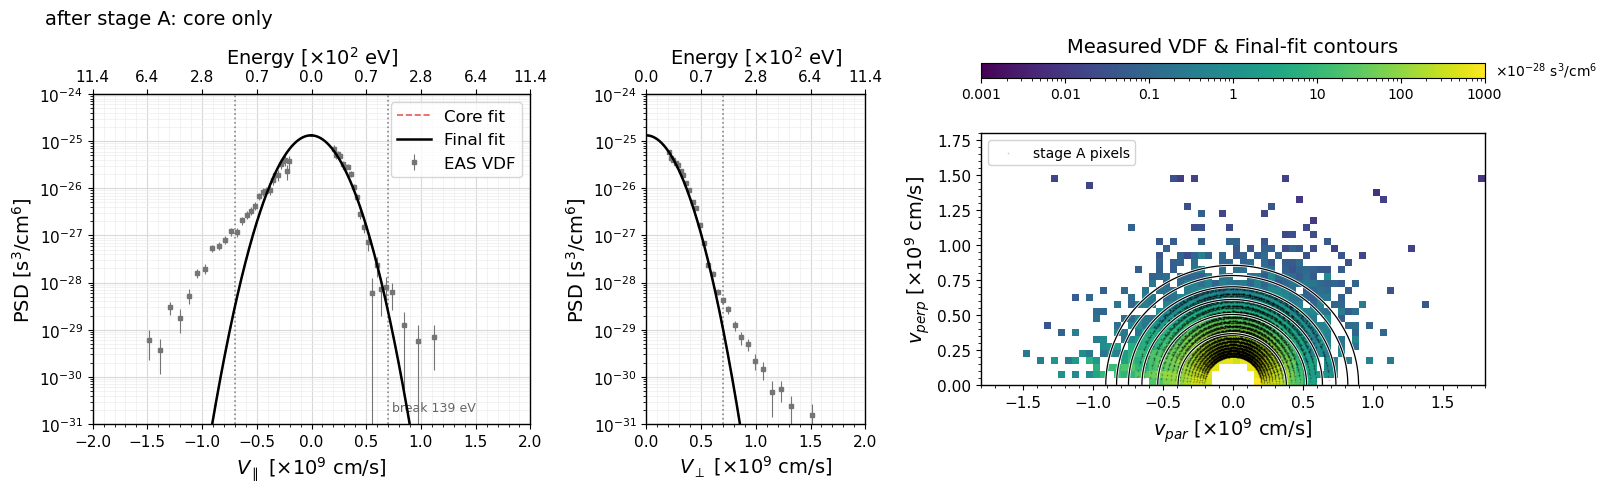

In [4]:
fig = plotMeasuredVdf(grid, psd, counts, componentsOnly(snapshots['A_core']['params'], ['core']),
                      breakEnergyEv=breakEnergyEv, highlightMask=snapshots['A_core']['mask'],
                      highlightLabel='stage A pixels', timeLabel='after stage A: core only')

## Stage B: the halo

- **Pixels:** $E > E_\text{break}$, **outside both 30 deg cones** around $\pm$**B** (no
  strahl, no sunward deficit).
- **Free:** the 5 halo parameters: density, drift, two widths, $\kappa$. The core is
  frozen at its stage-A value.
- Initial values and ranges are rebuilt from the *fitted* core:

| parameter | initial value | allowed range |
|---|---|---|
| $n_h$ | $0.03\, n_c^\text{fit}$ | $[10^{-5},\ 0.2] \times n_c^\text{fit}$ |
| $u_{\parallel h}$ | 0 | $\pm 0.2\, v_{th\perp h}^\text{seed}$ |
| $v_{th\parallel h}$, $v_{th\perp h}$ | $\sqrt{5}\, v_{th c}^\text{fit}$ ($T_h = 5\,T_c$) | $\ge 2 \times$ the fitted core width |
| $\kappa_h$ | 5 | $[2,\ 12]$ |

What the ranges are for:

- **widths $\ge$ 2x the core width:** the halo cannot become a second core;
- **$\kappa_h \ge 2$:** it cannot become a spike under the core peak (a bi-kappa's
  central amplitude grows as $(\kappa - 3/2)^{-3/2}$, and stage B never sees the centre);
- **$|u_{\parallel h}| \le 0.2$ halo widths:** the halo may counter-drift against the
  strahl (zero-current condition) but cannot slide onto an undetected strahl wing.
  `fitEpoch(..., freeHaloDrift=False)` (runner: `--fix-halo-drift`) pins the drift at
  zero.

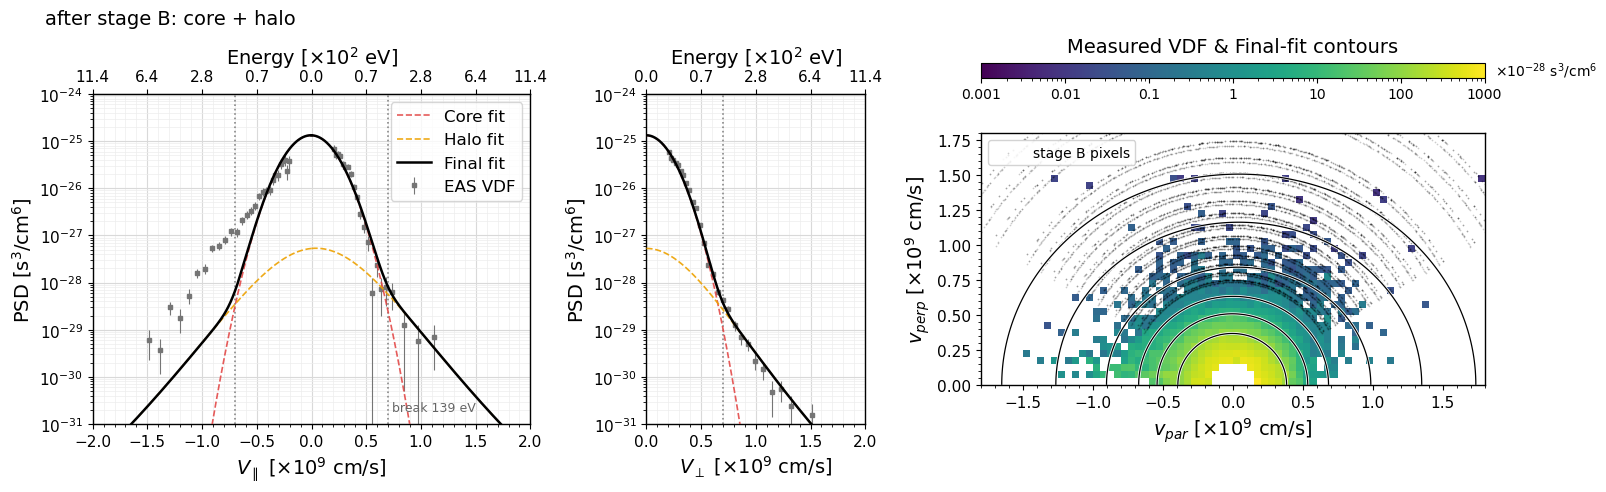

In [5]:
fig = plotMeasuredVdf(grid, psd, counts, componentsOnly(snapshots['B_halo']['params'], ['core', 'halo']),
                      breakEnergyEv=breakEnergyEv, highlightMask=snapshots['B_halo']['mask'],
                      highlightLabel='stage B pixels', timeLabel='after stage B: core + halo')

## Stage C: the strahl

Runs only if the PAD found a beam.

- **Pixels:** the 30 deg cone on the strahl side, **all** energies. The frozen core and
  halo bridge the thermal range, so the whole cone profile constrains the beam.
- **Free:** density, drift, parallel width and $\kappa$. The perpendicular width
  follows the drift through the PAD width,
  $v_{th\perp b} = \tan(\text{PAW}/2)\,|u_{\parallel b}|$.

| parameter | initial value | allowed range |
|---|---|---|
| $n_b$ | $0.01\, n_{sc}$ | $[0,\ 0.5\, n_{sc}]$ |
| $u_{\parallel b}$ | sign $\times\ 0.9\, v_\text{break}$ | sign $\times [0.3,\ 3]\, v_\text{break}$ |
| $v_{th\parallel b}$ | $0.5\, v_\text{break}$ | $[2\times10^7,\ 1.5\times10^9]$ cm/s |
| $v_{th\perp b}$ | $\tan(\text{PAW}/2)\,\lvert u_{\parallel b}\rvert$ | tied to $u_{\parallel b}$ during this stage |
| $\kappa_b$ | 5 | $[1.7,\ 20]$ |

The lower drift limit keeps the strahl suprathermal. Without it the component
degenerates into a second drifting core.

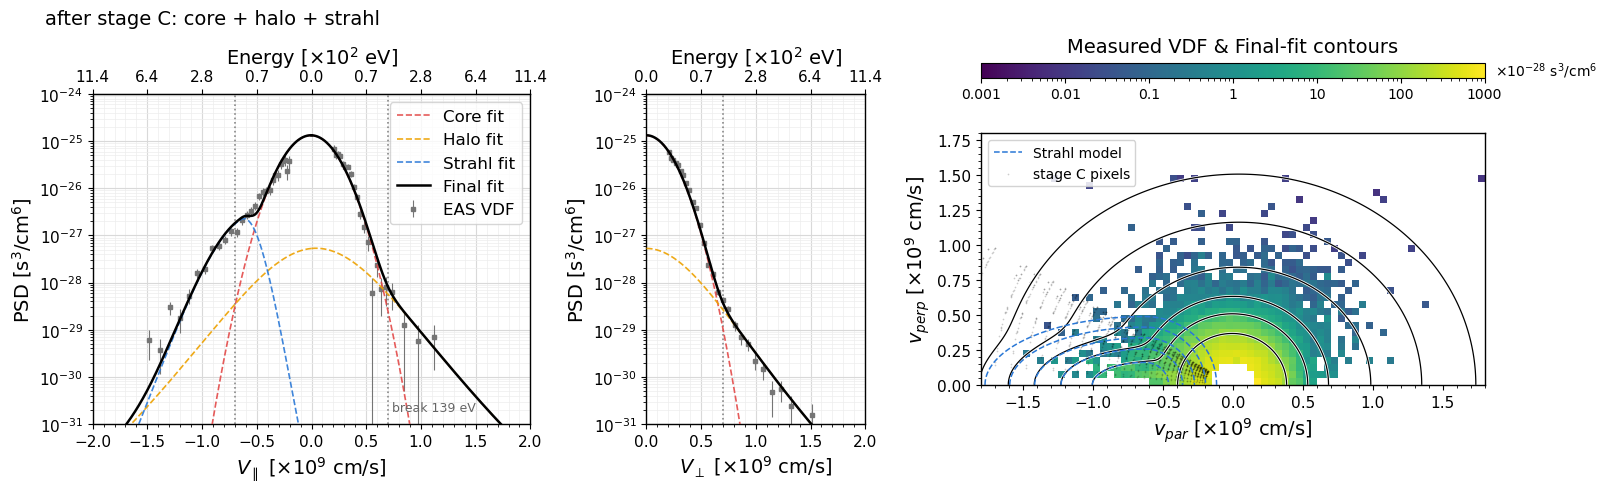

In [6]:
fig = plotMeasuredVdf(grid, psd, counts, snapshots['C_strahl']['params'],
                      breakEnergyEv=breakEnergyEv, highlightMask=snapshots['C_strahl']['mask'],
                      highlightLabel='stage C pixels', timeLabel='after stage C: core + halo + strahl')

## Stage D: joint refinement

- **Pixels:** all valid pixels.
- **Free:** all 14 parameters (9 without a strahl), each inside its range from the
  previous stages.
- The strahl drift is locked to $\pm 20\,\%$ of its stage-C value; its perpendicular
  width may move within $[0.3, 3]$ times its anchor.

This is the result the pipeline reports. The four-panel figure is the standard
diagnostic, also written by the batch runner: cuts, 2D distribution with contours,
deviance pull per pixel.

deviance/dof = 0.609   reduced chi2 (detected pixels) = 0.853   free parameters = 14   break source = crossing


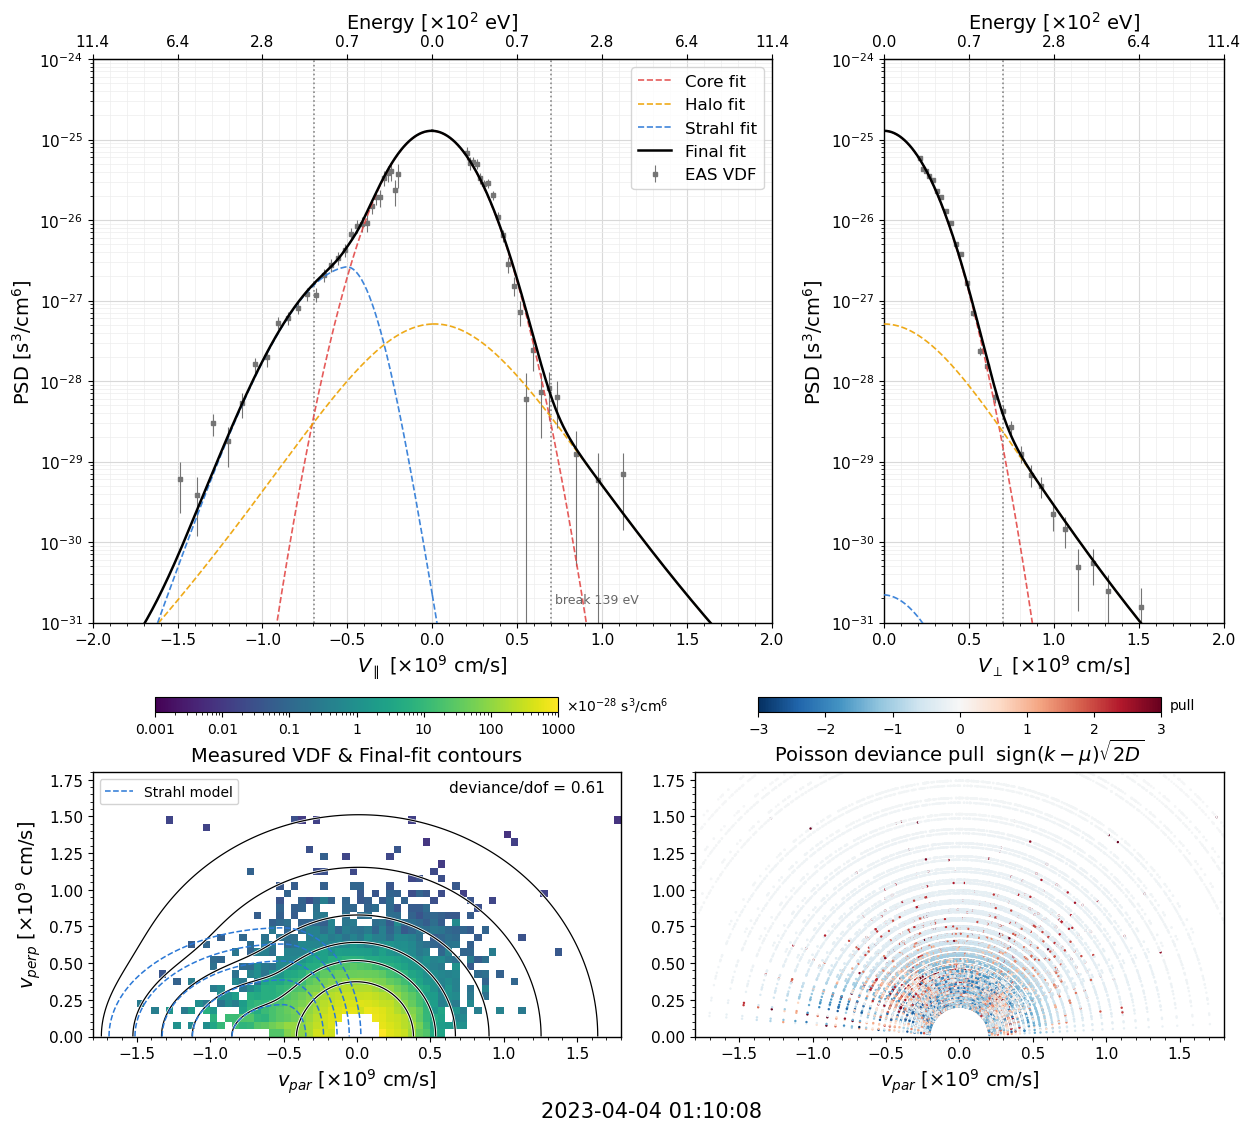

In [7]:
from evdf_poisson import poissonDeviancePerDof, reducedChiSquare
from evdf_poisson.plotting import plotPoissonFitEpoch

deviancePerDof = poissonDeviancePerDof(modelPsd, counts, grid, diagnostics['free_params'])
redChi2 = reducedChiSquare(modelPsd, psd, counts, grid, diagnostics['free_params'])
print(f'deviance/dof = {deviancePerDof:.3f}   reduced chi2 (detected pixels) = {redChi2:.3f}   '
      f'free parameters = {diagnostics["free_params"]}   break source = {diagnostics["break_source"]}')
fig = plotPoissonFitEpoch(grid, psd, counts, params, diagnostics, deviancePerDof, str(epochTime))

## How good is the fit?

- **`deviance_per_dof`** = $D$ / (pixels minus free parameters). **Not** expected to be
  1: the expected deviance of a pixel is well below 1 when its expected counts $\mu$ are
  small, as in most EAS pixels. The value tracks how bright the plasma is, so compare
  epochs of similar brightness.
- **Calibrated ratio** $R = D / \sum_i \mathrm{E}[D_i \mid \mu_i]$: the deviance relative
  to what a perfect model would give on this grid. $R \approx 1$: as good as Poisson
  noise allows. $R$ well above 1: structure the model does not describe. Notebook 08
  builds quality flags on it.
- **`red_chi2`**: classical reduced chi-square on detected pixels
  ($\sigma = f/\sqrt{C}$). For comparison with the literature only; it cannot see the
  zero-count pixels (notebook 07).
- **Pull map** (bottom right of the four-panel figure): *where* the deviance comes
  from. Red/blue speckle is noise. A coherent patch of one colour is a model
  deficiency: a sunward deficit, a strahl broader than a bi-kappa, secondaries at the
  low-energy edge.

this epoch: deviance/dof = 0.609   median expected counts per pixel = 0.060   calibrated ratio R = 1.123   reduced chi2 (detected pixels) = 0.853


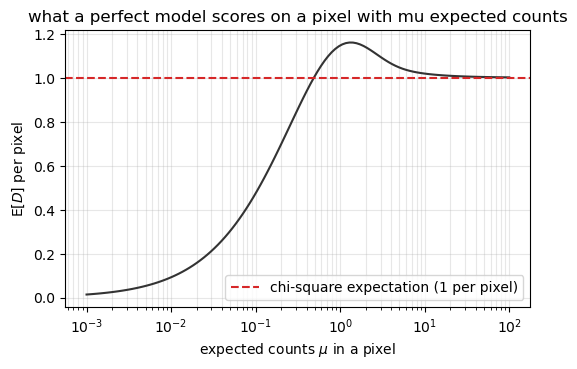

In [8]:
from scipy.stats import poisson

def expectedDeviancePerPixel(expectedCounts, maxCount=400):
    """E[D | mu] of a Poisson pixel: sum over k of P(k | mu) * d(k, mu); maxCount must exceed the largest mu by far."""
    k = np.arange(maxCount + 1)[:, None]
    mu = np.asarray(expectedCounts)[None, :]
    with np.errstate(divide='ignore', invalid='ignore'):
        logTerm = np.where(k > 0, k * np.log(k / mu), 0.0)
    deviance = 2.0 * (mu - k + logTerm)
    return np.sum(poisson.pmf(k, mu) * deviance, axis=0)

muCurve = np.logspace(-3, 2, 120)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx(muCurve, expectedDeviancePerPixel(muCurve), color='0.2')
ax.axhline(1, color='#d62728', linestyle='--', label='chi-square expectation (1 per pixel)')
ax.set_xlabel(r'expected counts $\mu$ in a pixel'); ax.set_ylabel(r'E[$D$] per pixel')
ax.set_title('what a perfect model scores on a pixel with mu expected counts'); ax.grid(alpha=0.3, which='both'); ax.legend()

valid = grid['valid']
expectedCounts = modelPsd[valid] / grid['one_count_psd'][valid]
observedDeviance = deviancePerDof * (valid.sum() - diagnostics['free_params'])
calibratedRatio = observedDeviance / expectedDeviancePerPixel(expectedCounts).sum()
print(f'this epoch: deviance/dof = {deviancePerDof:.3f}   median expected counts per pixel = {np.median(expectedCounts):.3f}   '
      f'calibrated ratio R = {calibratedRatio:.3f}   reduced chi2 (detected pixels) = {redChi2:.3f}')

## 3. Reading the result

The fit parameters are thermal speeds in cm/s; `componentMomentsFromParams` converts
them to temperatures in eV. The table follows each quantity through the stages: the
core barely moves after stage A, halo and strahl settle in their own stages, and the
joint stage adjusts everything by a few per cent.

In [9]:
stageMoments = {stageName: componentMomentsFromParams(snapshot['params']) for stageName, snapshot in snapshots.items()}
stageTable = pd.DataFrame(stageMoments)
stageTable.loc[['n_h', 'u_par_h', 'T_par_h_eV', 'T_perp_h_eV', 'kappa_h'], 'A_core'] = np.nan   # not fitted yet
stageTable.loc[['n_b', 'u_par_b', 'T_par_b_eV', 'T_perp_b_eV', 'kappa_b'], ['A_core', 'B_halo']] = np.nan
stageTable.map(lambda value: '' if np.isnan(value) else f'{value:.4g}')

,A_core,B_halo,C_strahl,D_joint
n_c,9.226,9.226,9.226,9.378
u_par_c,-5.562e+06,-5.562e+06,-5.562e+06,-4.388e+06
T_par_c_eV,16.48,16.48,16.48,16.81
T_perp_c_eV,14.74,14.74,14.74,15.41
n_h,,0.2135,0.2135,0.1852
u_par_h,,4.159e+07,4.159e+07,1.291e+07
T_par_h_eV,,74.58,74.58,68.42
T_perp_h_eV,,58.95,58.95,58.95
kappa_h,,5.617,5.617,5.071
n_b,,,0.07754,0.1347


**Pinned parameters.** A free parameter that ends within 0.1 % of the edge of its
range was decided by the range, not by the data. The batch runner lists them in
`pinned_params`. Two are expected:

- **halo widths on their lower limit** (twice the core width): the deviance is flat
  along the halo width;
- **strahl drift on the lower edge of its $\pm 20\,\%$ lock**: the joint stage pulls the
  beam down-energy to patch the core-strahl transition, and the lock decides how far.

The table marks the pinned parameters of this epoch.

In [10]:
from evdf_poisson.runner import findPinnedParams

pinned = findPinnedParams(params, diagnostics['param_bounds'])
boxTable = pd.DataFrame({name: {'value': f'{params[name]:.4g}', 'box low': f'{low:.4g}', 'box high': f'{high:.4g}',
                                'pinned': 'yes' if name in pinned else ''}
                         for name, (low, high) in diagnostics['param_bounds'].items()}).T
boxTable

,value,box low,box high,pinned
n_c,9.378,0,48.66,
u_par_c,-4.388e+06,-1.5e+08,1.5e+08,
v_th_par_c,2.432e+08,1e+07,8e+08,
v_th_perp_c,2.328e+08,1e+07,8e+08,
n_h,0.1852,9.226e-05,1.845,
u_par_h,1.291e+07,-1.077e+08,1.077e+08,
v_th_par_h,4.906e+08,4.815e+08,2.153e+09,
v_th_perp_h,4.554e+08,4.554e+08,2.153e+09,yes
kappa_h,5.071,2,12,
n_b,0.1347,0,12.17,


## 4. The same in one call

`fitOneEpoch` does all of the above (load, PAD, initial guesses, fit, metrics) and
returns the row the batch runner writes to CSV. Its numbers are identical to the
step-by-step ones and to the reference `summary.csv`.

In [11]:
import json
from evdf_poisson import fitOneEpoch

row = fitOneEpoch(EXAMPLE_FILE, EPOCH, breakEnergyEv=breakEnergyEv)
reference = pd.read_csv(RESULTS_DIR / 'summary.csv').set_index('epoch_index').loc[EPOCH]
print('identical to the step-by-step fit:', json.loads(row['fit_params_json']) == {k: float(v) for k, v in params.items()})
print('identical to the reference summary.csv:', json.loads(row['fit_params_json']) == json.loads(reference['fit_params_json']))
pd.Series(row).drop('fit_params_json')

/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


identical to the step-by-step fit: True
identical to the reference summary.csv: True


epoch_index                          20
objective                       poisson
epoch_ns            1680570608000000000
time_iso            2023-04-04 01:10:08
n_sc                          24.330587
n_c                            9.377649
u_par_c_cms             -4388262.280912
T_par_c_eV                    16.814685
T_perp_c_eV                   15.412832
n_h                            0.185209
u_par_h_cms             12913616.582805
T_par_h_eV                    68.416604
T_perp_h_eV                   58.948813
kappa_h                        5.071218
n_b                            0.134694
u_par_b_cms           -503191519.074335
T_par_b_eV                    32.762614
T_perp_b_eV                   12.767669
kappa_b                       16.293227
n_total                        9.697552
deviance_per_dof               0.609446
red_chi2                       0.852835
strahl_sign                          -1
break_energy_eV              139.034105
break_source                   crossing
